# 2. Fit and compare LDA models

We compare seven topic counts on the shared full corpus, then choose a model as a team.
Run notebook 01 first. Each fit uses 100 batch variational-Bayes iterations and symmetric
priors of 1/K, the scikit-learn defaults. This is a new grid, distinct from the historical
20-iteration study.

Coherence, diversity, topic sizes, and nonreserved example articles inform selection.
Training perplexity is an LDA diagnostic, not held-out performance or a BERTopic accuracy score.

In [1]:
from pathlib import Path
import json, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').exists())
ROOT = REPO/'final-project/code/classical-methods'
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT.parent))
from shared.corpus import CORPUS_DIR, audit_corpus, load_corpus, corpus_hash, digest, write_json
from shared import evaluation as ev
import lda as ld
import representation as rep
import interpret as interpretation
import export as artifacts
OUT = ROOT.parent/'modern-methods/Results/classical'
MODERN = ROOT.parent/'modern-methods/Results/modern'
OUT.mkdir(parents=True, exist_ok=True)

In [2]:
df = load_corpus()
reservation = artifacts.load_reservation(MODERN/'review_sample.json', df)
X, vocabulary, preparation = rep.load_representation(df, OUT/'cache/representation')
texts, dictionary = ev.reference_texts(df)
implementation = artifacts.implementation_hash(ROOT, ROOT/'notebooks/02_classical_topic_modeling.ipynb')
execution_rows = []

## Fit the models

The sparse count matrix and vocabulary remain fixed across K. Each completed fit is checkpointed
before evaluation. Complete runs are loaded only when their identities and file hashes match.
An interrupted grid can resume. A stale run must be preserved separately before refitting.

We time fitting, shared coherence/perplexity evaluation, and mixture/example exports separately.
Original fitting times remain unchanged on cache loads. Models are trusted local pickle files.

In [3]:
def fit_configuration(k, seed=42):
    """One verified LDA fit; the experiment choices are visible here."""
    run_id = f'lda_k{k}_s{seed}'
    folder = OUT/'runs'/run_id
    parameters = dict(k=k, seed=seed, max_iter=100, learning_method='batch',
                      doc_topic_prior=None, topic_word_prior=None, n_jobs=1,
                      min_df=5, max_df=0.5, top_n_words=10, representative_count=3)
    identity = artifacts.run_identity(df, preparation, parameters, implementation, reservation)
    started = time.perf_counter()
    if (folder/'manifest.json').exists():
        model, manifest = artifacts.load_run(folder, expected=identity)
        execution_rows.append(dict(run_id=run_id, action='verified cache load', seconds=time.perf_counter()-started))
        print(run_id, '— reused verified run', flush=True)
        return model, manifest
    checkpoint = artifacts.load_checkpoint(folder, identity)
    if checkpoint is None:
        print(run_id, '— fitting 100 iterations', flush=True)
        model, fit_seconds = ld.fit_lda(X, k, seed, max_iter=parameters['max_iter'],
            learning_method=parameters['learning_method'], doc_topic_prior=parameters['doc_topic_prior'],
            topic_word_prior=parameters['topic_word_prior'])
        artifacts.save_checkpoint(folder, model, identity, fit_seconds)
    else:
        model, fit_seconds = checkpoint
        print(run_id, '— reused completed fit; finishing evaluation', flush=True)
    evaluated = time.perf_counter()
    terms = ld.top_terms(model, np.asarray(vocabulary), n=10)
    per_topic = ev.coherence(terms, texts, dictionary)
    metrics = ld.score_run(model, X, terms, texts, dictionary, k, seed, fit_seconds, per_topic=per_topic)
    metrics['evaluation_seconds'] = time.perf_counter()-evaluated
    metrics.update(topic_count=k, outlier_fraction=0.0, max_iter=parameters['max_iter'])
    exported = time.perf_counter()
    artifacts.export_run(model, X, df, terms, per_topic, folder, run_id, reservation['article_ids'])
    timings = dict(preparation['timings'], fit_seconds=fit_seconds,
                   evaluation_seconds=metrics['evaluation_seconds'],
                   interpretation_export_seconds=time.perf_counter()-exported)
    artifacts.save_run_manifest(folder, identity, metrics, timings)
    execution_rows.append(dict(run_id=run_id, action='fit and evaluate' if checkpoint is None else 'resume evaluation',
                               seconds=time.perf_counter()-started))
    print(f"{run_id}: coherence={metrics['coherence']:.3f}, perplexity={metrics['perplexity']:.0f}, fit={fit_seconds:.1f}s", flush=True)
    return model, json.loads((folder/'manifest.json').read_text())

In [4]:
K_GRID = [10, 20, 30, 40, 50, 60, 70]
grid_rows = []
for k in K_GRID:
    _, manifest = fit_configuration(k, seed=42)
    grid_rows.append(manifest['metrics'])
    # Save completed rows after each run; each run also has its own manifest.
    pd.DataFrame(grid_rows).to_csv(OUT/'experiments.csv', index=False)
experiments = pd.DataFrame(grid_rows)
write_json(OUT/'execution.json', execution_rows)
display(experiments[['run_id','topic_count','coherence','vocabulary_coverage','keyword_diversity','perplexity','fit_seconds']])

lda_k10_s42 — reused verified run
lda_k20_s42 — reused verified run
lda_k30_s42 — reused verified run
lda_k40_s42 — reused verified run
lda_k50_s42 — reused verified run
lda_k60_s42 — reused verified run
lda_k70_s42 — reused verified run


,run_id,topic_count,coherence,vocabulary_coverage,keyword_diversity,perplexity,fit_seconds
0,lda_k10_s42,10,0.649574,1.0,0.850000,3499.189535,134.000210
1,lda_k20_s42,20,0.634264,1.0,0.780000,3312.899544,150.248752
2,lda_k30_s42,30,0.629560,1.0,0.763333,3253.466710,160.406187
3,lda_k40_s42,40,0.654585,1.0,0.707500,3223.658667,170.230846
4,lda_k50_s42,50,0.649019,1.0,0.724000,3191.670227,182.449875
5,lda_k60_s42,60,0.651515,1.0,0.720000,3202.431586,186.872548
6,lda_k70_s42,70,0.649463,1.0,0.700000,3226.589483,206.233783


## Review topic quality and choose a model

Read each run's local `representatives.csv` for article evidence. We select the three highest
per-topic probabilities among nonreserved articles, breaking ties by article ID. A representative
may have another dominant topic, especially for a topic with few or no dominant articles; its
probability and dominant topic are recorded. These are development examples, not random evaluation.

Check small, redundant, and low-coherence topics as well as the largest topics. The tables show
IDs and titles without displaying reserved article text. Coherence uses ten unigrams, the shared
reference tokenizer, and 110-token windows. Report vocabulary coverage alongside it.

lda_k10_s42 — largest topics


,topic_id,keywords,count,coherence,representative_article_ids
5,5,"ford, electric, automakers, industry, driving,...",1342,0.608746,1651888 | 253602 | 47374
0,0,"driving, road, lidar, sensors, human, driver, ...",1093,0.621596,2448440 | 512733 | 1096200
3,3,"uber, waymo, testing, lyft, public, test, driv...",1000,0.645357,1365942 | 110861 | 2788503
2,2,"transportation, cities, people, city, trucks, ...",861,0.489621,350083 | 672188 | 302791
6,6,"data, apple, google, learning, intelligence, s...",623,0.495279,466029 | 439902 | 1850658


Lowest coherence:


,topic_id,keywords,count,coherence
2,2,"transportation, cities, people, city, trucks, ...",861,0.489621
6,6,"data, apple, google, learning, intelligence, s...",623,0.495279
5,5,"ford, electric, automakers, industry, driving,...",1342,0.608746


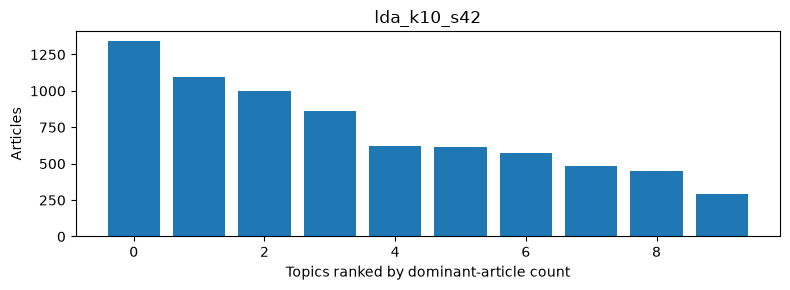

lda_k20_s42 — largest topics


,topic_id,keywords,count,coherence,representative_article_ids
0,0,"driving, lidar, road, sensors, driver, drive, ...",922,0.644085,1355698 | 1332151 | 798188
12,12,"waymo, service, testing, test, delivery, publi...",836,0.635355,411571 | 499278 | 1555133
19,19,"tech, driving, software, intel, china, industr...",574,0.463225,876108 | 333021 | 790004
5,5,"ford, electric, auto, automakers, motors, crui...",550,0.742277,47374 | 987483 | 186413
15,15,"lyft, drivers, uber, transportation, cities, c...",535,0.477559,128077 | 1422445 | 1404262


Lowest coherence:


,topic_id,keywords,count,coherence
8,8,"flying, drones, drone, navigation, udacity, th...",46,0.435607
1,1,"jobs, workers, boundless, smart, aired, work, ...",44,0.461956
19,19,"tech, driving, software, intel, china, industr...",574,0.463225


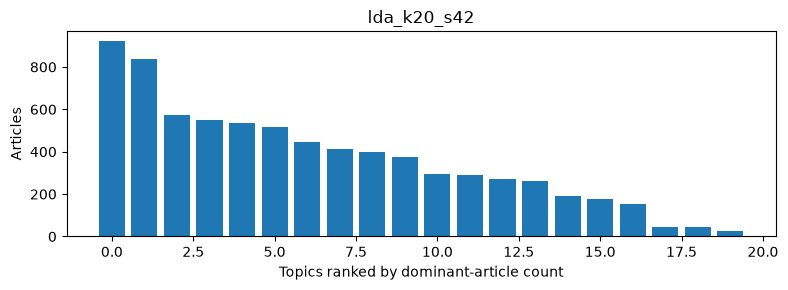

lda_k30_s42 — largest topics


,topic_id,keywords,count,coherence,representative_article_ids
0,0,"driving, road, driver, human, drivers, drive, ...",764,0.700402,1355698 | 1102830 | 354378
22,22,"lidar, cruise, ford, tech, sensors, driving, a...",599,0.532850,352192 | 545605 | 301249
7,7,"uber, levandowski, waymo, google, ubers, otto,...",465,0.825196,61037 | 1118052 | 331985
2,2,"safety, federal, transportation, rules, state,...",446,0.704649,931451 | 509506 | 221300
5,5,"ford, electric, auto, automakers, industry, vo...",400,0.712183,1001274 | 1515570 | 987483


Lowest coherence:


,topic_id,keywords,count,coherence
25,25,"people, percent, future, lives, industry, chan...",190,0.375839
20,20,"recode, originally, recodenet, appeared, artic...",36,0.392714
16,16,"people, york, times, news, world, didnt, tech,...",128,0.441840


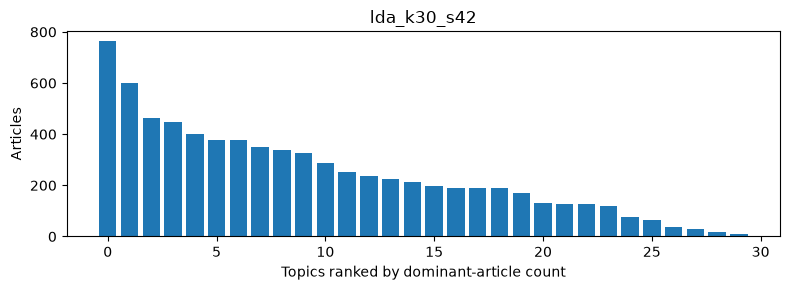

lda_k40_s42 — largest topics


,topic_id,keywords,count,coherence,representative_article_ids
0,0,"driving, driver, road, drivers, human, drive, ...",678,0.700402,1945070 | 354378 | 834089
22,22,"lidar, cruise, sensors, tech, working, softwar...",513,0.538699,301249 | 143578 | 343034
2,2,"safety, federal, transportation, rules, regula...",434,0.667987,730651 | 221300 | 1238961
7,7,"uber, levandowski, waymo, ubers, google, trade...",424,0.826547,61037 | 331985 | 1115380
19,19,"china, chinese, driving, baidu, toyota, daimle...",391,0.569714,49182 | 190212 | 975756


Lowest coherence:


,topic_id,keywords,count,coherence
25,25,"people, jobs, percent, work, workers, governme...",133,0.456379
16,16,"city, university, bus, shuttle, local, driverl...",73,0.461637
15,15,"driving, transportation, driverless, industry,...",145,0.475662


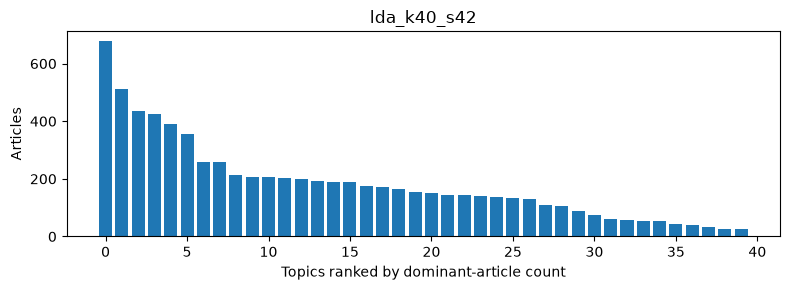

lda_k50_s42 — largest topics


,topic_id,keywords,count,coherence,representative_article_ids
0,0,"driving, driver, drivers, road, human, wheel, ...",600,0.694805,1340018 | 1332151 | 834089
22,22,"tech, uber, partnership, announced, automakers...",474,0.522820,2070644 | 519768 | 286607
7,7,"uber, levandowski, waymo, google, ubers, trade...",406,0.826547,61037 | 1118052 | 331985
2,2,"safety, federal, transportation, rules, state,...",380,0.751883,1238961 | 1176973 | 1267035
47,47,"lidar, sensors, intel, systems, mobileye, nvid...",379,0.689326,303375 | 288948 | 497893


Lowest coherence:


,topic_id,keywords,count,coherence
20,20,"wireless, network, byton, charging, home, goog...",6,0.322433
9,9,"volvo, software, hotz, driving, safety, featur...",30,0.395036
8,8,"hyundai, south, saudi, korea, korean, samsung,...",9,0.397468


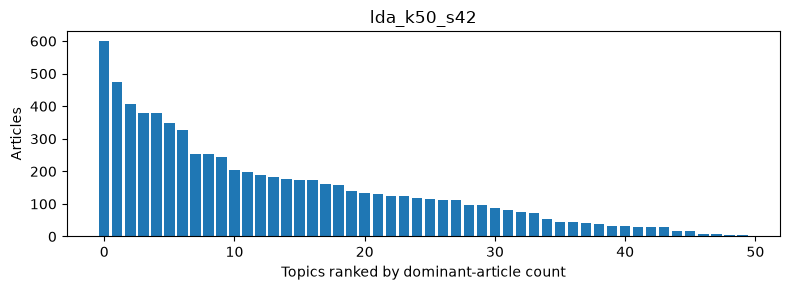

lda_k60_s42 — largest topics


,topic_id,keywords,count,coherence,representative_article_ids
22,22,"uber, tech, partnership, announced, working, f...",486,0.513290,2070644 | 542075 | 1108766
0,0,"driving, driver, drivers, road, human, wheel, ...",478,0.731799,834089 | 1354928 | 1071107
7,7,"uber, levandowski, waymo, trade, ubers, secret...",436,0.860100,92766 | 1923479 | 433539
56,56,"intel, driving, mobileye, automotive, systems,...",304,0.631647,1347867 | 1371099 | 1166606
2,2,"safety, federal, rules, states, nhtsa, regulat...",301,0.723534,888566 | 793457 | 770322


Lowest coherence:


,topic_id,keywords,count,coherence
13,13,"hyundai, south, yandex, itaposs, zhang, driver...",32,0.296197
48,48,"design, rental, images, image, adversarial, mo...",9,0.321328
14,14,"blackberry, ups, tusimple, software, qnx, firm...",28,0.363553


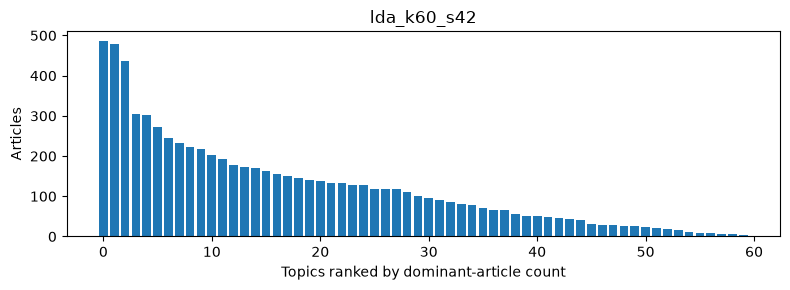

lda_k70_s42 — largest topics


,topic_id,keywords,count,coherence,representative_article_ids
0,0,"driving, driver, drivers, road, human, wheel, ...",540,0.713906,1340018 | 1945070 | 1333849
22,22,"tech, driving, automakers, partnership, announ...",431,0.464244,2070644 | 520696 | 446927
7,7,"uber, levandowski, waymo, trade, secrets, case...",369,0.860100,433539 | 498918 | 440418
61,61,"transportation, future, people, change, indust...",365,0.384187,1748926 | 335884 | 298230
3,3,"uber, testing, arizona, ubers, california, tes...",335,0.723909,778092 | 2735919 | 410850


Lowest coherence:


,topic_id,keywords,count,coherence
36,36,"video, dubai, shows, released, middle, view, b...",6,0.296701
62,62,"patent, patents, windowtaboola, jack, business...",29,0.313902
13,13,"hyundai, wireless, yandex, south, altman, pony...",33,0.345816


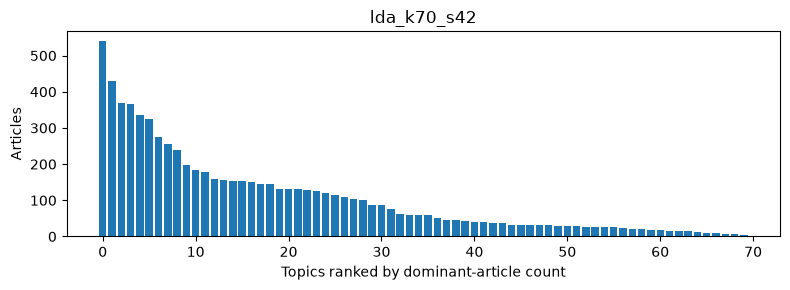

Team selection pending: fill Results/classical/selection.json with run_id, rationale, and selected_by.


In [5]:
for run_id in experiments.run_id:
    folder = OUT/'runs'/run_id
    inventory = interpretation.topic_inventory(folder, folder, len(df))
    print(run_id, '— largest topics')
    display(inventory.nlargest(5,'count')[['topic_id','keywords','count','coherence','representative_article_ids']])
    print('Lowest coherence:')
    display(inventory.nsmallest(3,'coherence')[['topic_id','keywords','count','coherence']])
    fig, ax = plt.subplots(figsize=(8,3))
    ax.bar(np.arange(len(inventory)), inventory.sort_values('count',ascending=False)['count'])
    ax.set(xlabel='Topics ranked by dominant-article count',ylabel='Articles',title=run_id)
    fig.tight_layout()
    for extension in ['png','pdf']: fig.savefig(folder/f'topic_sizes.{extension}',dpi=180)
    plt.show()
    plt.close(fig)
selection = artifacts.selection_record(OUT, df, experiments.run_id.tolist())
if selection is None:
    print('Team selection pending: fill Results/classical/selection.json with run_id, rationale, and selected_by.')

## Check stability and name the selected topics

K=40 remains a historical candidate; it is not selected automatically. Record the team's choice
in `selection.json`, explaining the metrics and nonreserved article evidence. Then rerun this
notebook to fit the same K with seeds 7 and 21.

ARI compares aligned dominant assignments. LDA assigns all articles, so its evaluated fraction
is 100%, unlike BERTopic's assigned-only ARI. Publication changes match topics by article overlap;
topic numbers do not have the same meaning across seeds. Inspect split/merge evidence too.

Fill `proposed_label`, `evidence_notes`, and `confirmed` in the selected run's label table. Evidence
IDs must belong to that topic's supplied development examples. Edits survive reruns. Confirm names
before independent human review; do not use the reserved articles for this task.

In [6]:
if selection is not None:
    selected_run = selection['run_id']
    k = int(experiments.set_index('run_id').loc[selected_run,'k'])
    _, baseline_manifest = fit_configuration(k)
    SELECTED = OUT/'selected'/selected_run
    SELECTED.mkdir(parents=True, exist_ok=True)
    write_json(SELECTED/'selection.json', selection)
    baseline = pd.read_csv(OUT/'runs'/selected_run/'assignments.csv',dtype={'article_id':str})
    stability_rows = []
    for seed in [7,21]:
        _, other_manifest = fit_configuration(k, seed)
        other = pd.read_csv(OUT/'runs'/other_manifest['metrics']['run_id']/'assignments.csv',dtype={'article_id':str})
        summary = ev.seed_publication_comparison(df, baseline, other, SELECTED/f'seed_{seed}')
        stability_rows.append(dict(seed=seed, **summary))
    stability = pd.DataFrame(stability_rows)
    stability.to_csv(SELECTED/'stability.csv',index=False)
    display(stability)
    label_identity = dict(run_id=selected_run,corpus_hash=corpus_hash(df),run_identity_hash=digest(baseline_manifest['identity']))
    labels = interpretation.labels_table(OUT/'runs'/selected_run, SELECTED, label_identity)
    display(labels)
else:
    print('Selected-model seed checks and labels pending team choice.')
write_json(OUT/'execution.json', execution_rows)

Selected-model seed checks and labels pending team choice.


## Next steps and limits

Notebook 03 exports topic inventories, publication results, and the selected-model handoff.
LDA probabilities describe mixed membership; they are not the same measure as HDBSCAN membership
strength. We retain all mixtures, even though the comparison uses dominant assignments.

These are full-corpus exploratory results. Held-out evaluation and comparisons over shared date
ranges remain later work for both pipelines. No topic model alone measures sentiment or public opinion.